# Sensitivity analysis for MARINADE-NPZD

This notebook demonstrates a sensitivity analysis for a one-year realistic GOTM-NPZD setting (compare Burchard, 2005 for a description of the setup).

We first re-produce the Fortran GOTM-NPZD output with MARINADE (PyTorch).

Next, we use forward-mode automatic differentiation for an efficient sensitivity computation.

Finally, we evaluate the sensitivities with a finite-difference approximation.

Important: In order to run this notebook, you will require a few additional files:

- *gotm.yaml* and
- *fabm.yaml* for the GOTM scenario "rouse" (https://github.com/gotm-model/cases/tree/master/rouse), slightly modified
- *initial_sed.txt*, the initial tracer profile
- *rouse.nc*, the GOTM output based on those files

Those can be obtained from Zenodo.

### DOWNLOAD FORCING FILES FROM ZENODO

The required files can be obtained on Zenodo: <https://zenodo.org/uploads/23670437>

Please save the folder *marinade_github_forcing_data* to the following location:

In [ ]:
base_folder = '/gpfs/work/nimtz/zenodo/'  # the directory of your Zenodo download
path = base_folder + 'marinade_github_forcing_data/nns_npzd/base_simulation_1y/'

filename = f'nns_annual.nc'
fabm_yaml_name = 'fabm.yaml'
gotm_yaml_name = f'gotm.yaml'

### Setup of the simulation

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mc
from matplotlib.ticker import FormatStrFormatter

import numpy as np
import torch
from torch.func import jacfwd
from tensordict import TensorDict

import pickle
import netCDF4 as nc

from time import time as time_function

from marinade.fabm.gotm_npzd_model import GOTMNPZDModel
from marinade.fabm.gotm_light_model import GOTMLightModel
from marinade.gotm.gotm import initialize_gotm, TracerSimulationOperator

We load GOTM model outputs used as forcing data:

In [ ]:
ds = nc.Dataset(path+filename, dtype="float64")

I_0_npzd = ds['I_0'][:].squeeze()

h = torch.from_numpy(ds["h"][:].data.squeeze()).unsqueeze_(0).unsqueeze_(2)
h = torch.from_numpy(np.array(h, dtype="float64"))
nu = torch.from_numpy(ds["nuh"][:].data.squeeze()).unsqueeze_(0).unsqueeze_(2)
nu = torch.from_numpy(np.array(nu, dtype="float64"))
time = torch.from_numpy(ds['time'][:])
t = ds['time'][:]
z = ds['z'][:].data.squeeze()[:]
zi = ds['zi'][:].data.squeeze()[:]

The variables stored in the GOTM output file are:

In [ ]:
print('dimensions:')
for name, dim in ds.dimensions.items():
    print(f'{name}: {len(dim)}')
print()
print('variables:')
for name, var in ds.variables.items():
    dims = ", ".join(var.dimensions)
    print(f"{name} ({dims}) {var.dtype}")

dimensions:
time: 8761
lon: 1
lat: 1
z: 110
zi: 111

variables:
time (time) float64
npzd_NPR (time, z, lat, lon) float64
npzd_PPR (time, z, lat, lon) float64
zeta (time, lat, lon) float64
evap (time, lat, lon) float64
precip (time, lat, lon) float64
I_0 (time, lat, lon) float64
h (time, z, lat, lon) float64
nuh (time, zi, lat, lon) float64
salt (time, z, lat, lon) float64
temp (time, z, lat, lon) float64
npzd_det (time, z, lat, lon) float64
npzd_zoo (time, z, lat, lon) float64
npzd_phy (time, z, lat, lon) float64
npzd_nut (time, z, lat, lon) float64
lon (lon) float32
lat (lat) float32
z (time, z, lat, lon) float32
zi (time, zi, lat, lon) float32


### Run full simulation

We first reproduce the GOTM simulation (Fortran) with MARINADE (PyTorch).

In [ ]:
initialization_dict = initialize_gotm(path+gotm_yaml_name, path+fabm_yaml_name, path+filename, model_classes=[GOTMLightModel, GOTMNPZDModel], device='cpu', dtype='float64')

h, nu, dt, t, z, zi = [initialization_dict[key] for key in ("h", "nu", "dt", "t", "z", "zi")]

initial_state_pelagic = initialization_dict["init_state_tensors"][1]
ts_pelagic = initialization_dict["full_ts_tensors"][1]
dynamic_inputs = initialization_dict["dynamic_inputs"]

In [ ]:
light_model, npzd_model = initialization_dict["models"]
coupled_model = light_model.couple(npzd_model)

forward_operator = TracerSimulationOperator(
    bc_up_type_dif="neumann", bc_down_type_dif="neumann", bc_up_value_dif=0., bc_down_value_dif=0.,
    bc_up_type_adv="flux", bc_down_type_adv="flux", bc_up_value_adv=0., bc_down_value_adv=0.,
    scheme_adv="p2_pdm", conserve=False, implicitness=1., allow_negative=False, model=coupled_model)
parameters_original = forward_operator.model.get_parameters().clone()

We simulate one year of NPZD model dynamics with MARINADE:

In [ ]:
initial_state_dict = TensorDict({"pelagic": initial_state_pelagic}, batch_size=initial_state_pelagic.shape[:1])
initial_state_dict = light_model.compute_light(initial_state_dict, dt, dynamic_inputs[:, 0])
 
t0 = time_function()
simulation = forward_operator.integrate(
    initial_state_dict,
    dt,
    h,
    nu,
    dynamic_inputs=dynamic_inputs,
)
print(f'Total time for the simulation: {time_function() - t0} seconds')

simulation_tensor = simulation["pelagic"]

Total time for the simulation: 96.0653190612793 seconds


We define functions for the visualization:

In [ ]:
def show_tracer_ts(ts_, ax=None, title=None, label_colorbar=None,
                   cbar_rotation=None, cbar_labelpad=None, cbar_loc=None, cbar_orientation='vertical', cbar_extend=None,
                   cmap=None, norm=None, vmin=None, vmax=None, center_on_zero=False,
                   t_=t, z_=z, xlabel=None, ylabel="$z$ [m]", shading=None,
                   x_stride=1, y_stride=1, aspect=20):
    if ax is None:
        ax = plt.gca()
    if isinstance(ts_, TensorDict):
        ts_ = ts_['pelagic']
    if center_on_zero:
        vmax_abs = torch.max(torch.abs(ts_[~ts_.isnan()]))
        vmin, vmax = -vmax_abs, vmax_abs
    pcol = ax.pcolormesh(t_[::x_stride]/60**2/24, z_.T[::y_stride, ::x_stride], ts_.squeeze().T[::y_stride, ::x_stride], cmap=cmap, vmin=vmin, vmax=vmax, norm=norm, shading=shading)
    cbar = plt.colorbar(pcol, ax=ax, aspect=aspect, label=label_colorbar, orientation=cbar_orientation, extend=cbar_extend)
    if cbar_rotation is not None:
        cbar.set_label(label_colorbar, rotation=cbar_rotation, labelpad=cbar_labelpad, loc=cbar_loc)
    #for i in range(0, z_.shape[1], z_.shape[1]//10):
        #ax.plot(t_/60**2, z_[:, i], ls='--', c='gray', label=f"layer {i}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

def warped_cmap(cmap, gamma=0.5, N=256):
    x = np.linspace(0, 1, N)
    x_warped = x**gamma   # <-- non-linear remapping
    _colors = cmap(x_warped)
    return mc.ListedColormap(_colors)

def warped_cmap_two_sided(cmap, gamma=0.5, N=256):
    x = np.linspace(-1, 1, N)
    x_warped = np.abs(x)**gamma*np.sign(x)   # <-- non-linear remapping
    _colors = cmap((x_warped+1)/2)
    return mc.ListedColormap(_colors)

We compute errors:

In [ ]:
error_abs = simulation_tensor[:][...,:,:] - ts_pelagic[:,:,:,:]
error_rel = error_abs / ts_pelagic

We compare the Fortran and PyTorch simulations and check for consistency:

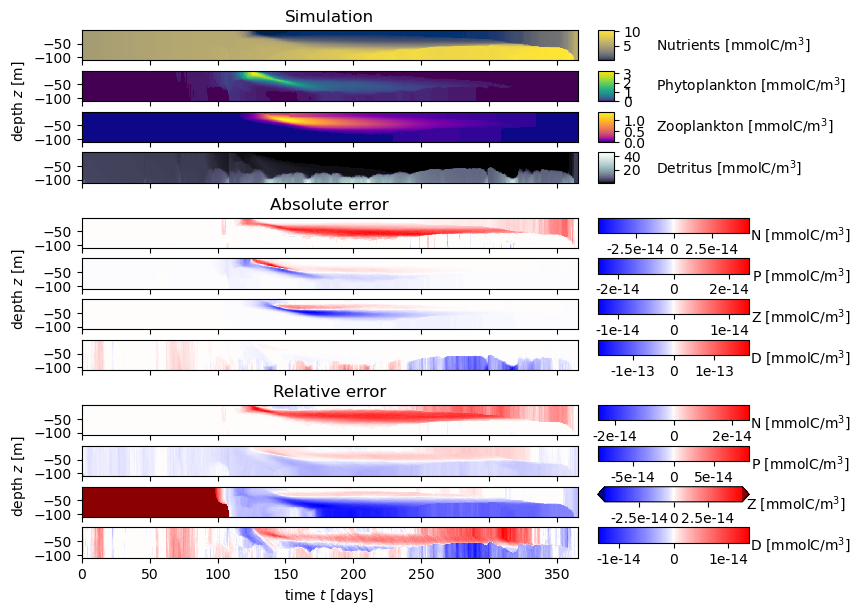

In [ ]:
fig, ax = plt.subplots(12, 1, sharex=True, figsize=(8,7))

titles_assimilated = ["Simulation", "Absolute error", "Relative error"]
tracers_long = ["Nutrients [mmolC/m$^3$]", "Phytoplankton [mmolC/m$^3$]",
                "Zooplankton [mmolC/m$^3$]", "Detritus [mmolC/m$^3$]"]
tracers_assimilated = ["N [mmolC/m$^3$]", "P [mmolC/m$^3$]", "Z [mmolC/m$^3$]", "D [mmolC/m$^3$]"]
cmaps = ["cividis", "viridis", "plasma", "bone"]

cmap_err = warped_cmap_two_sided(
    plt.get_cmap("bwr"),
    gamma=0.8
).copy()

cmap_err.set_over("darkred")
cmap_err.set_under("darkblue")

idx = 1
aspect_v = 2
aspect_h = 10
for i in range(4):
    show_tracer_ts(ts_pelagic[0,:,i,:], t_=t, z_=z, ax=ax[i], cbar_rotation=0, cbar_labelpad=40, label_colorbar=tracers_long[i], cmap=warped_cmap(plt.get_cmap(cmaps[i])), ylabel=None, x_stride=10, y_stride=2, aspect=aspect_v)
    show_tracer_ts(error_abs[0,:,i,:], t_=t, z_=z, ax=ax[i+4], cbar_rotation=0, label_colorbar=tracers_assimilated[i], cmap=cmap_err, cbar_orientation='horizontal', cbar_loc='right', norm=mc.CenteredNorm(), ylabel=None, x_stride=10, y_stride=2, aspect=aspect_h)
    if i == 2:
        _vmax = error_rel[0,4000:,i,:].abs().max()
        show_tracer_ts(error_rel[0,:,i,:], t_=t, z_=z, ax=ax[i+8], cbar_rotation=0, label_colorbar=tracers_assimilated[i], cmap=cmap_err, cbar_orientation='horizontal', cbar_extend='both', norm=mc.CenteredNorm(halfrange=_vmax), ylabel=None, x_stride=10, y_stride=2, aspect=aspect_h)
    else:
        show_tracer_ts(error_rel[0,:,i,:], t_=t, z_=z, ax=ax[i+8], cbar_rotation=0, label_colorbar=tracers_assimilated[i], cmap=cmap_err, cbar_orientation='horizontal', norm=mc.CenteredNorm(), ylabel=None, x_stride=10, y_stride=2, aspect=aspect_h)
for i in range(3):
    ax[4*i].set_title(titles_assimilated[i])
ax[-1].set_xlabel("time $t$ [days]")
cbar_axes = [a for a in fig.axes if a not in ax]
inner_gap = 0.015
group_gap = 0.05
x0, _, w, _ = ax[0].get_position().bounds
top = ax[0].get_position().y1
bottom = ax[-1].get_position().y0
total_height = top - bottom
height = (total_height - 9*inner_gap - 2*group_gap) / 12
current_y = top
for g in range(3):
    ax[g*4+2].set_ylabel("depth $z$ [m]", loc='bottom')
    for i in range(4):
        idx = g*4 + i
        idx_cbar = i*3 + g
        ax_pos = [x0, current_y - height, w, height]
        ax[idx].set_position(ax_pos)
        cax = cbar_axes[idx_cbar]
        cx0, _, cw, _ = cax.get_position().bounds
        if g == 0:
            cax.set_position([cx0*0.984, current_y - height, cw, height])
            cax.yaxis.label.set_horizontalalignment('left')
            cax.yaxis.label.set_verticalalignment('center')
            cax.yaxis.set_label_coords(3.8, 0.5)
        else:
            cax.set_position([cx0*3.82, current_y - height*0.5, cw, height*0.5])
            cax.yaxis.label.set_horizontalalignment('left')
            cax.yaxis.label.set_verticalalignment('center')
            cax.xaxis.set_label_coords(2.0-g*0.33 + (0.05 if i==2 and g==2 else 0), 0.5, transform=None)
            cax.xaxis.set_major_formatter(FormatStrFormatter('%g'))
        current_y -= height + inner_gap
    current_y -= group_gap - inner_gap

The GOTM and MARINADE simulations should match up to numerical double precision.

### Sensitivity analysis of MARINADE-NPZD simulation

Next, we use forward-mode automatic differentiation to compute sensitivities of the simulation with respect to the NPZD model parameters.

First, we list the parameters, then we perform the forward-mode autodiff:

In [ ]:
parameter_dict = forward_operator.model.get_parameters()
parameter_names = list(parameter_dict.keys())
parameter_values = list(parameter_dict.values())
print('i  parameter    value')
print('---------------------------------------')
for i, (_name, _val) in enumerate(zip(parameter_names, parameter_values)):
    print(f'{i:2d}', _name.ljust(10), '=', _val.item())#, parameter_dict[_name].item())

i  parameter    value
---------------------------------------
 0 light_a    = 0.58
 1 light_g1   = 0.35
 2 light_g2   = 23.0
 3 p0         = 0.0225
 4 z0         = 0.0225
 5 kc         = 0.03
 6 i_min      = 25.0
 7 rmax       = 1.1574074074074073e-05
 8 gmax       = 2.3148148148148148e-06
 9 iv         = 1.1
10 alpha      = 1.35
11 rpn        = 1.1574074074074074e-07
12 rzn        = 1.1574074074074074e-07
13 rdn        = 3.472222222222222e-08
14 rpdu       = 2.3148148148148148e-07
15 rpdl       = 1.1574074074074074e-06
16 rzd        = 2.3148148148148148e-07
17 dic_per_n  = 6.625
18 w_p        = -1.1574074074074073e-05
19 w_d        = -5.787037037037037e-05


In [ ]:
def f(*args):
    forward_operator.model.update_parameters(TensorDict({_name: _factor*_val for _name, _val, _factor in zip(parameter_names, parameter_values, args)}))

    initial_state_dict = TensorDict({"pelagic": initial_state_pelagic}, batch_size=initial_state_pelagic.shape[:1])
    initial_state_dict = forward_operator.model.compute_light(initial_state_dict, dt, dynamic_inputs[:, 0])

    t0 = time_function()
    simulation = forward_operator.integrate(
        initial_state_dict,
        dt,
        h,
        nu,
        dynamic_inputs=dynamic_inputs,
    )
    print(f'Total time for the simulation: {time_function() - t0} seconds')
    _res = simulation['pelagic']
    return _res, _res

grad, res = jacfwd(f, argnums=tuple(range(len(parameter_names))), has_aux=True)(*torch.ones(len(parameter_names), dtype=torch.float64))

Total time for the simulation: 309.88025188446045 seconds


We can now visualize the sensitivities of the simulation with respect to the parameter values:

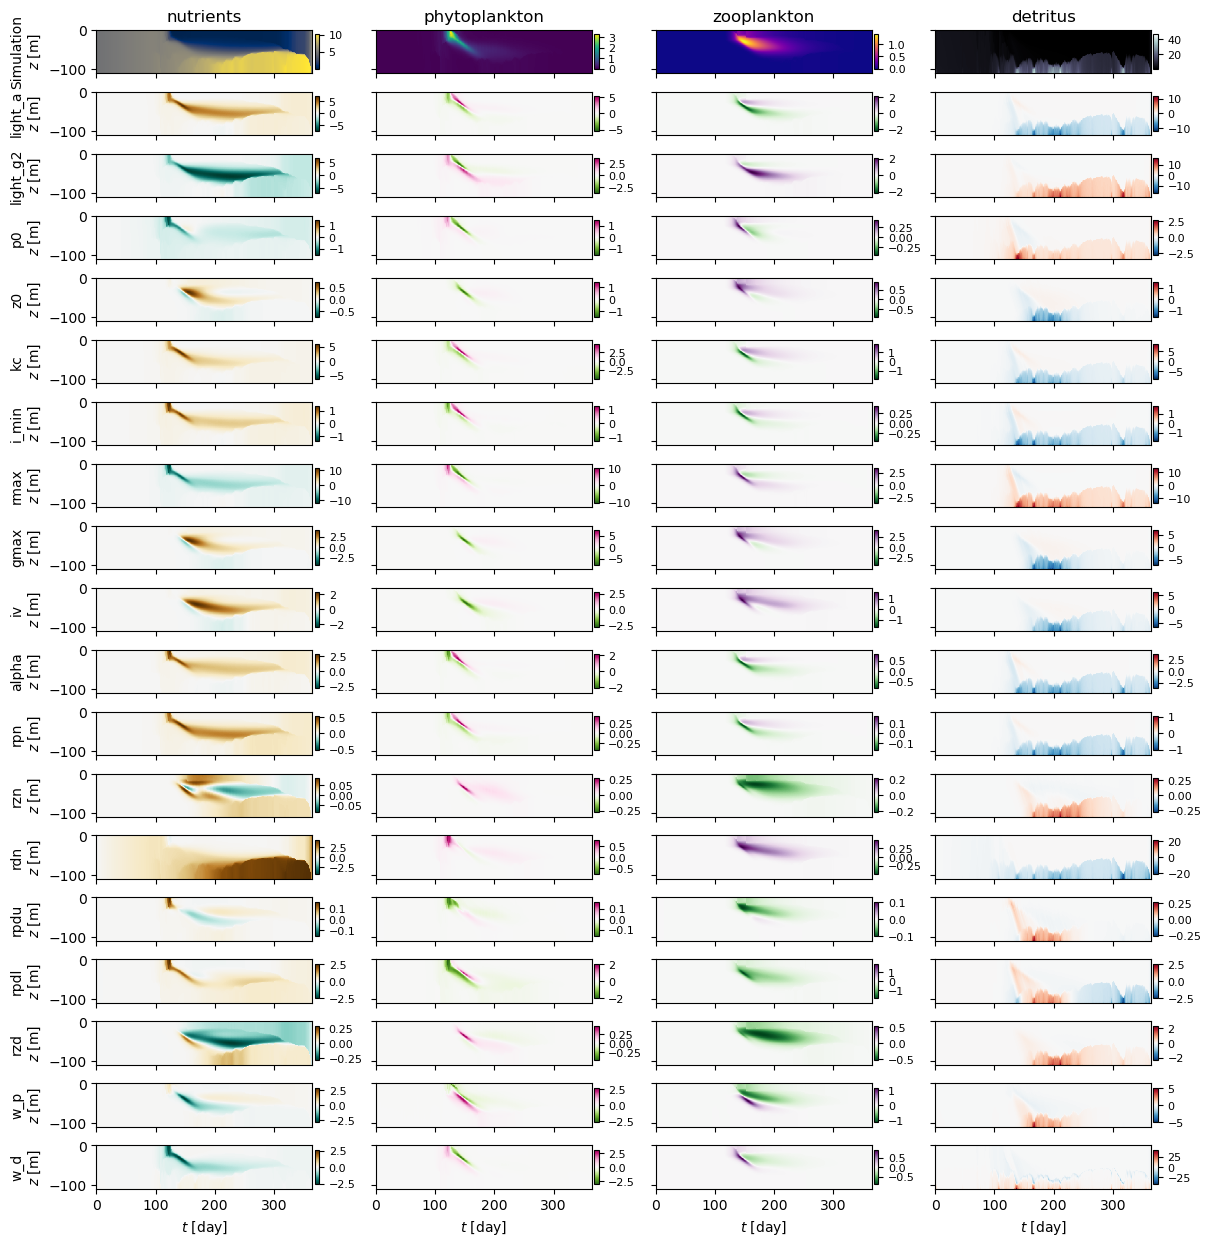

In [ ]:
species = ["nutrients", "phytoplankton", "zooplankton", "detritus"]
cmaps_grad = ["BrBG_r", "PiYG_r", "PRGn_r", "RdBu_r"]
valid = [(x, name) for x, name in zip(grad, parameter_names) if name not in ("light_g1", "dic_per_n")]
nrows = 1 + len(valid)
fig, ax = plt.subplots(nrows, 4, sharex=True, sharey=True, figsize=(12, 0.65 * nrows), constrained_layout=True)
ax = np.atleast_2d(ax)
for j in range(4):
    pcm = ax[0, j].pcolormesh(t/60**2/24, z.T, res[0, :, j, :].T, cmap=cmaps[j])
    ax[0, j].set_title(species[j])
    cbar = fig.colorbar(pcm, ax=ax[0, j], pad=0.01, shrink=0.8, aspect=8,)
    cbar.ax.tick_params(labelsize=8)
ax[0, 0].set_ylabel("Simulation\n$z$ [m]")
for i, (x, name) in enumerate(valid, start=1):
    for j in range(4):
        pcm = ax[i, j].pcolormesh(t/60**2/24, z.T, x[0, :, j, :].T, cmap=cmaps_grad[j], norm=mc.CenteredNorm())
        cbar = fig.colorbar(pcm, ax=ax[i, j], pad=0.01, shrink=0.8, aspect=8)
        cbar.ax.tick_params(labelsize=8)
    ax[i, 0].set_ylabel(f"{name}\n$z$ [m]")
for a in ax[-1, :]:
    a.set_xlabel("$t$ [day]")
plt.show()

For a more compact visualization, we consider the vertically integrated sensitivities:

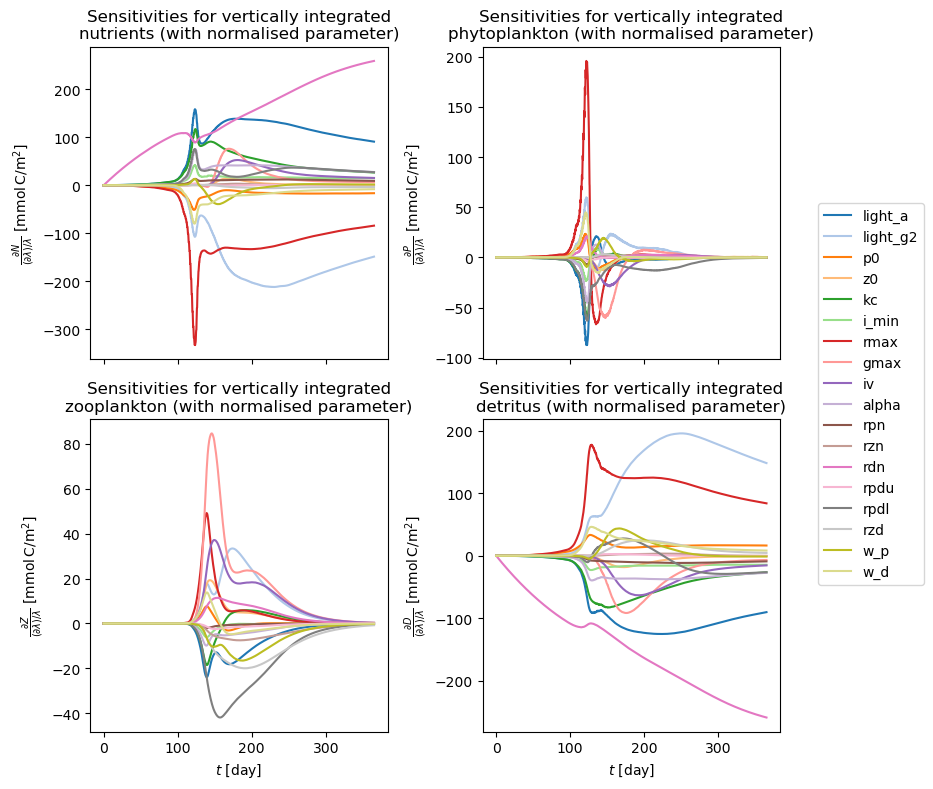

In [ ]:
fig, ax_2d = plt.subplots(2, 2, sharex=True, figsize=(8, 8))
ax = ax_2d.flat
_colors = plt.cm.tab20(np.linspace(0, 1, 20))
j = 0
for _grad, _name in zip(grad, parameter_names):
    if not _name in ('light_g1', 'dic_per_n'):
        _int = ((_grad * h).sum(dim=-1)).squeeze()
        for i in range(4):
            ax[i].plot(t/60**2/24, _int[:, i], color=_colors[j % 20], label=_name)
        j += 1
for _ax in ax_2d[-1]:
    _ax.set_xlabel("$t$ [day]")
for i, _var in enumerate(['nutrients', 'phytoplankton', 'zooplankton', 'detritus']):
    ax[i].set_title(f'Sensitivities for vertically integrated\n{_var} (with normalised parameter)')
for i, _var in enumerate(['N', 'P', 'Z', 'D']):
    ax[i].set_ylabel(f'$\\frac{{\\partial {_var}}}{{(\\partial\\lambda)/\\lambda}}$ [mmol$\\,$C/m$^2$]')
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout(rect=[0, 0, 1, 1])
plt.show()

For a quantitative comparison of per-parameter sensitivities, we compare time-averaged vertically integrated sensitivities to obtain a table of scalar values:

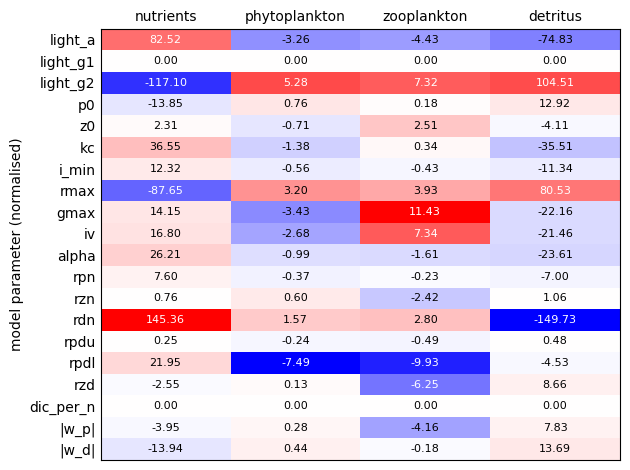

In [ ]:
_grads = (torch.cat(grad)*h).sum(dim=-1).mean(dim=1)

for i in range(4):
    plt.pcolormesh(np.arange(2)+i, np.arange(21)[::-1], _grads[:,i:i+1], cmap='bwr', norm=mc.CenteredNorm())
    # write values into cells
    for j in range(_grads.shape[0]):
        text_color = 'white' if abs(_grads[-1-j,i]) > 0.5 * _grads[:,i].abs().max() else 'black'
        plt.text(i + 0.5, j + 0.5, f"{_grads[-1-j, i]:.2f}", ha='center', va='center', fontsize=8, color=text_color)
plt.xticks(np.arange(4)+0.5, ('nutrients', 'phytoplankton', 'zooplankton', 'detritus'))
plt.gca().xaxis.tick_top()
plt.gca().tick_params(length=0)
_yticks = [_s if i < 18 else f'|{_s}|' for i, _s in enumerate(parameter_names)]
plt.yticks(np.arange(len(parameter_names))+0.5, _yticks[::-1])
plt.ylabel('model parameter (normalised)')
plt.tight_layout()
plt.show()

# Finite difference approximation

Now, we validate these sensitivity values with a finite difference approximation, utilizing the definition of the derivative:

$\frac{\partial c_{\lambda}(z,t)}{\partial \lambda} = \lim_{\epsilon \to 0} \frac{c_{\lambda+\epsilon}(z,t)-c_{\lambda}(z,t)}{\epsilon}$

For increasingly small values of $\epsilon$, the finite difference approximation should converge to the analytic value of the derivative. We thus consider a range of $\epsilon_i$:

In [ ]:
epsilon_0 = 0.1
n_epsilon = 20
epsilon = epsilon_0*torch.exp(-torch.arange(n_epsilon, dtype=torch.float64))

We define the range of parameters for which we compute finite difference approximations.

HINT: since the following computations are expensive, you might want to restrict this selection.

In [ ]:
indices = [0,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,18,19]
# indices = [7, 8]

print('Parameters estimated with finite difference approximations:\n')
print('i λ_i\n----------')
for i in indices:
    print(i, parameter_names[i])

Parameters estimated with finite difference approximations:

i λ_i
----------
0 light_a
2 light_g2
3 p0
4 z0
5 kc
6 i_min
7 rmax
8 gmax
9 iv
10 alpha
11 rpn
12 rzn
13 rdn
14 rpdu
15 rpdl
16 rzd
18 w_p
19 w_d


WARNING: the following code might run for multiple hours. You might prefer to load the results from disk with the following commands.

In [ ]:
mean_grads_e_all = []
i = 8
for i in indices:
    print(i, parameter_names[i])
    _grads_e = []
    for _e in epsilon:
        factors = torch.ones(len(parameter_names), dtype=torch.float64)
        factors[i] += _e
        print(_e.item(), factors[i].item())
        with torch.no_grad():
            res_1, _ = f(*factors)
        _grad = res_1 - res
        _grads_e.append((_grad*h)[0].sum(dim=-1).mean(dim=0))
    _grads_e = torch.stack(_grads_e)
    mean_grads_e_all.append(_grads_e)
mean_grads_e_all = torch.stack(mean_grads_e_all, dim=1)

In [ ]:
with open(f'mean_grads_e_all_{epsilon_0}.pkl', 'wb') as file:
    pickle.dump(mean_grads_e_all, file)

In [ ]:
with open(f'mean_grads_e_all_{epsilon_0}.pkl', 'rb') as file:
    mean_grads_e_all = pickle.load(file)

We now plot the root mean squared relative errors of the finite difference approximations depending on the finite difference $\varepsilon$:

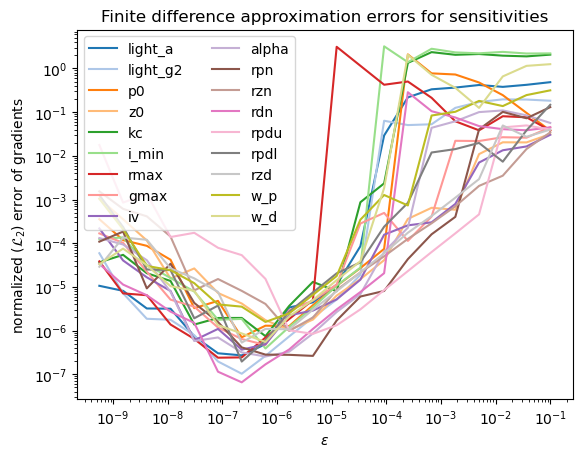

In [ ]:
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.tab20.colors)
plt.plot(epsilon, ((mean_grads_e_all/epsilon[:,None,None] - _grads[indices]) / _grads[indices]).square().mean(dim=-1).sqrt(), label=[parameter_names[i] for i in indices])
plt.xlabel('$\epsilon$'); plt.ylabel('normalized ($\mathcal{L}_2$) error of gradients')
plt.title('Finite difference approximation errors for sensitivities')
plt.legend(ncols=2); plt.xscale('log'); plt.yscale('log'); plt.show()

For large finite differences, the relative estimation errors are high. For smaller finite differences, the estimates become more accurate (up to relative errors $<10^{-5}$ at $\varepsilon=10^{-6}$), but for finite differences below $10^{-7}$, the estimate errors increase again. We attribute this to numerical errors at increasingly smaller differences.